In [1]:
# set the path to analosis relative to this notebook
import sys
sys.path.append('../..')

# import the Run class which allows you to run the analysis of your choice
from analosis.run import Run

In [2]:
cosmology = {'id': 'planck18', 'H0': 67.4, 'Om': 0.315}

### Image settings
We now impose the settings used to generate the images.
* `generate_image`: can be True or False. If true, generates a new set of images and associated data. If false, looks for pre-existing image data with the name you passed, which can be plotted or fit with the MCMC.
* `number_of_images`: the number of images you want to generate or analyse. For analysing pre-generated images, this setting is ignored.
* `image_name`: the name under which the image files will be saved
* `lens_light`: True or False. Whether or not to add lens light to the image. If lens light is present, it is automatically fit by the MCMC.
* `truth_model`: the mass model used to generate the mocks. Use `'composite'` for the original baryons+halo mocks, or `'boxydisky'` to generate power-law mocks with an injected `a_4` term.
* `a4_max`: when `truth_model` is `'boxydisky'`, `a4_a` is drawn uniformly from `[-a4_max, +a4_max]`.
* `maximum_shear`: the maximum value the LOS shears can take
* `Einstein_radius_min`: the minimum allowed Einstein radius in arcsecs
* `min_aspect_ratio_*`: the minimum aspect ratio for the source, baryon and halo ellipticities
* `maximum_source_offset_factor`: the maximum value for the offset of the source from the centre of the image
* `max_source_perturbations`: maximum number of additional Sersic profiles added to simulate a perturbed source
* `fixed_numpix`: True or False. Whether to fix the number of pixels in an image or scale the image size with the Einstein ring
* `sigma_halo_offset`: the offset of the halo from the baryonic part of the lens in parsecs


In [3]:
image_settings = {'generate_image': True,
                  'number_of_images': 24,
                  'image_name': 'Ring',
                  'lens_light': True,
                  'source': True, # False = no background galaxy (non-lens images)
                  'truth_model': 'boxydisky',
                  'a4_max': 0.1,
                  'telescope': 'HST',
                  'band': None,
                  'maximum_shear': 0.025, # any larger means gamma_LOS > 0.05 which is challenging for the MCMC
                  'Einstein_radius_min': 0.5, # arcsec
                  'min_aspect_ratio_source': 0.6,
                  'min_aspect_ratio_baryons': 0.6,
                  'min_aspect_ratio_nfw': 0.6,
                  'minimum_source_offset_factor': 0.0, # in units of Einstein radius
                  'maximum_source_offset_factor': 0.15, # in units of Einstein radius, values from 0 - 0.15 give full/clear rings, values 0.2 - 0.35 give half a ring or a long arc, 0.4 - 0.5 give short arcs and a small counter image (doubles). 
                  'max_source_perturbations': 5, # 3 additional Sersics with amplitudes that are randomly 0-5% of the main source
                  'fixed_numpix': True,
                  'sigma_halo_offset': 300} # pc

In [4]:
mcmc_settings = {'MCMC': False, 
                 'complexity': 'power_law_boxydisky',
                 'number_of_runs': 3, 
                 'starting_index': 0, 
                 'sampler': 'EMCEE', 
                 'job_name': 'my_job_boxydisky', 
                 'n_burn': 500, 
                 'n_run': 500} 


In [5]:
result = Run(cosmology, image_settings, mcmc_settings)

Adding between 1 and 5 sersic source perturbations per image.
MCMC will not be run.

Analysis complete and results saved at C:\Users\Fahim\SPC5001-analosis-wrap\analosis\results.


In [6]:
path = result.pathfinder()

In [7]:
from analosis.analysis.plots import Plots
p = Plots(cosmology, path)

Preparing image plot...


C:\Users\Fahim\SPC5001-analosis-wrap\analosis\notebooks\../..\analosis\analysis\plots.py:116: RuntimeWarning: invalid value encountered in log10
  im = ax.matshow(np.log10(image_list[n]), origin='lower', vmin=v_min, vmax=v_max, cmap=cmap, extent=[0, 1, 0, 1])


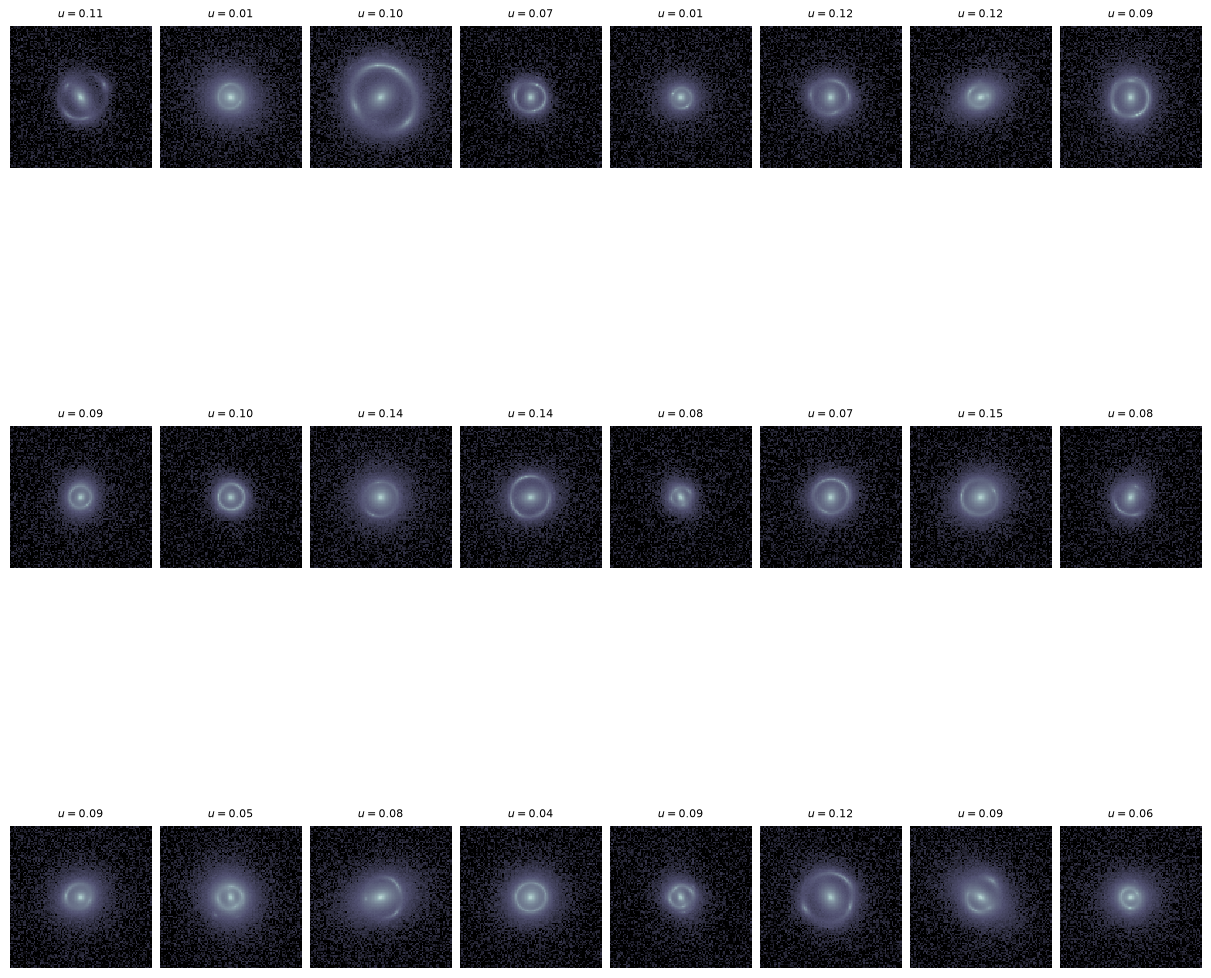

In [8]:
p.image_plot(path, image_settings, number_of_columns=8, u_max=10, save=False, show=True)